# Heart Rate Time Series Analysis


**Abstract:**
This project analyzes the heart rate (HR) time series of a healthy individual recorded over 24 hours using a wrist-worn actigraph device (MMASH dataset, PhysioNet) can be found on "https://physionet.org/content/mmash/1.0.0/". The data is resampled to per-minute averages to obtain a clean, regularly-spaced series of n ≈ 1,440 observations. Following the Box-Jenkins methodology, we identify, estimate, and validate ARIMA models, then generate short-horizon forecasts and compare them to withheld observations. The analysis reveals meaningful autocorrelation structure in resting HR, demonstrating that short-term heart rate dynamics can be captured by parsimonious ARIMA models.

---
## 1. Introduction

Heart rate (HR) is one of the most fundamental physiological signals in
cardiovascular medicine. Growing up with a cardiologist father, I was constantly
exposed to ECG recordings and the patterns he would study in his patients,
this early fascination with cardiac signals motivated me to apply time series
analysis to real heart rate data. Continuous HR monitoring over time reveals
patterns linked to circadian rhythms, physical activity, stress, and autonomic
nervous system regulation, making it a rich and clinically meaningful signal to
model. Understanding and forecasting short-term HR dynamics has practical
applications in patient monitoring, wearable health devices, and early detection
of cardiac anomalies such as arrhythmias and bradycardia.

In this project we analyze a 24-hour HR recording from the MMASH dataset
(Multilevel Monitoring of Activity and Sleep in Healthy people), publicly
available on PhysioNet. HR is measured in beats per minute (bpm) and sampled
every second; we aggregate to per-minute averages to reduce noise while
preserving the temporal structure. Our goal is to fit an appropriate ARIMA
model following the Box-Jenkins methodology, validate its residuals, and
produce a short-term forecast compared to withheld observations.

---
## 2. Setup

In [1]:
# Install packages
install.packages(c("forecast", "tseries", "dplyr", "ggplot2", "lubridate", "randtests"), quiet = TRUE)

also installing the dependencies ‘xts’, ‘TTR’, ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘quadprog’, ‘quantmod’




In [22]:
library(forecast)
library(tseries)
library(dplyr)
library(ggplot2)
library(lubridate)
library(randtests)

# Plot theme
theme_set(theme_minimal(base_size = 12) +
  theme(
    plot.title       = element_text(face = "bold", size = 13),
    panel.grid.minor = element_blank()
  ))

cat("All libraries loaded.\n")


Attaching package: ‘randtests’


The following object is masked from ‘package:tseries’:

    runs.test




All libraries loaded.


---
## 3. Model Specification

### 3.1 Data Preparation

In [3]:
df <- read.csv("Actigraph.csv", stringsAsFactors = FALSE)

cat("Dimensions:", nrow(df), "rows x", ncol(df), "cols\n")
head(df)

Dimensions: 67936 rows x 13 cols


,X,Axis1,Axis2,Axis3,Steps,HR,Inclinometer.Off,Inclinometer.Standing,Inclinometer.Sitting,Inclinometer.Lying,Vector.Magnitude,day,time
,<int>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<int>,<chr>
1,82,0,0,0,0,68,0,1,0,0,0.00,1,10:10:22
2,83,11,4,7,1,68,0,1,0,0,13.64,1,10:10:23
3,84,0,21,10,0,68,0,0,1,0,23.26,1,10:10:24
4,85,0,1,24,0,68,0,0,1,0,24.02,1,10:10:25
5,86,34,14,63,1,154,0,1,0,0,72.95,1,10:10:26
6,87,101,10,90,0,161,0,1,0,0,135.65,1,10:10:27


In [4]:
# Keep day 1 only for a clean 24h window
df <- df[df$day == 1, ]

# Parse time to minutes since midnight
df$time_parsed <- hms(df$time)
df$minutes     <- hour(df$time_parsed) * 60 + minute(df$time_parsed) + second(df$time_parsed) / 60

# Remove physiologically implausible HR values
df <- df[df$HR > 30 & df$HR < 220, ]

# Resample: per-minute averages
hr_by_min <- df %>%
  mutate(minute_bin = floor(minutes)) %>%
  group_by(minute_bin) %>%
  summarise(HR = mean(HR, na.rm = TRUE), .groups = "drop") %>%
  arrange(minute_bin) %>%
  filter(!is.na(HR))

cat("Series length (n):", nrow(hr_by_min), "\n")
cat("Mean HR:", round(mean(hr_by_min$HR), 1), "bpm\n")
cat("SD HR:  ", round(sd(hr_by_min$HR),   1), "bpm\n")
cat("Min HR: ", round(min(hr_by_min$HR),   1), "bpm\n")
cat("Max HR: ", round(max(hr_by_min$HR),   1), "bpm\n")

Series length (n): 830 
Mean HR: 90.7 bpm
SD HR:   12 bpm
Min HR:  62 bpm
Max HR:  133.8 bpm


In [5]:
# Withhold last 15 observations for forecast evaluation
n_holdout <- 15
n_total   <- nrow(hr_by_min)

hr_train <- ts(hr_by_min$HR[1:(n_total - n_holdout)], frequency = 1)
hr_test  <- ts(hr_by_min$HR[(n_total - n_holdout + 1):n_total], frequency = 1)

cat("Training set:", length(hr_train), "observations\n")
cat("Test set (withheld):", length(hr_test), "observations\n")

Training set: 815 observations
Test set (withheld): 15 observations


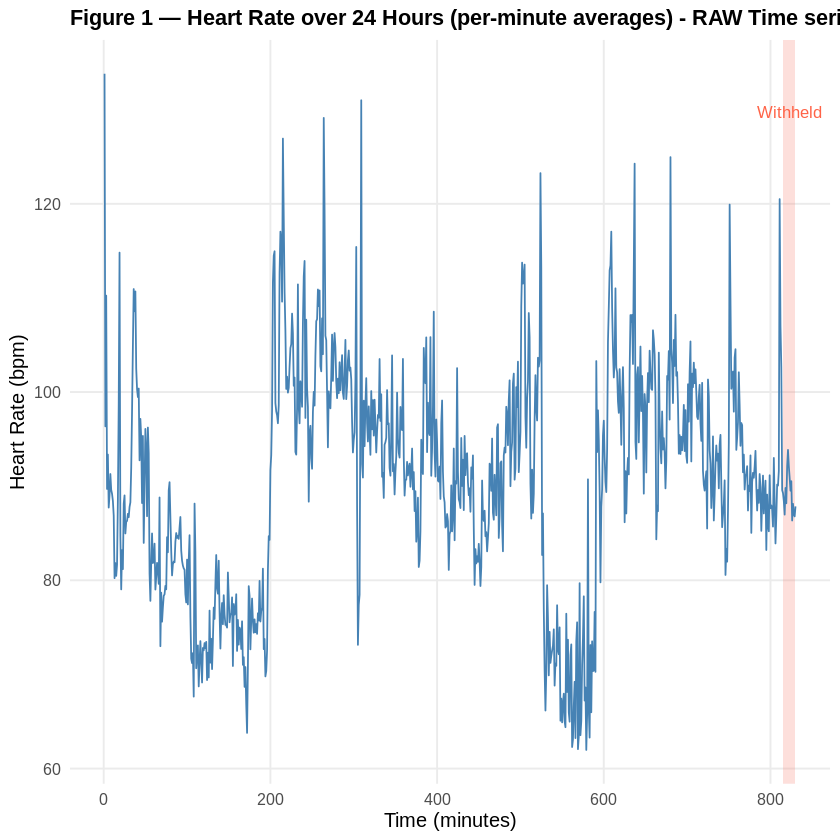

In [27]:
# Figure 1: Raw time series
hr_all <- ts(hr_by_min$HR, frequency = 1)
n_train <- length(hr_train)

plot_df <- data.frame(t = seq_along(hr_all), HR = as.numeric(hr_all))

ggplot(plot_df, aes(x = t, y = HR)) +
  annotate("rect",
           xmin = n_train, xmax = nrow(plot_df),
           ymin = -Inf,    ymax = Inf,
           fill = "salmon", alpha = 0.25) +
  geom_line(colour = "steelblue", linewidth = 0.5) +
  annotate("text", x = n_train + n_holdout / 2, y = max(plot_df$HR) * 0.97,
           label = "Withheld", colour = "tomato", size = 3.5) +
  labs(title = "Figure 1 — Heart Rate over 24 Hours (per-minute averages) - RAW Time series",
       x = "Time (minutes)", y = "Heart Rate (bpm)")

### 3.2 Variance Stabilization

We compare variance in the first and second halves of the series to assess whether a log transformation is needed.

In [7]:
half <- floor(length(hr_train) / 2)
var1 <- var(hr_train[1:half])
var2 <- var(hr_train[(half + 1):length(hr_train)])

cat("Variance first half: ", round(var1, 2), "\n")
cat("Variance second half:", round(var2, 2), "\n")
cat("Ratio (larger/smaller):", round(max(var1, var2) / min(var1, var2), 2), "\n\n")
cat("If ratio < 3 → variance stable, no log transform needed.\n")
cat("We proceed with the raw HR series.\n")

Variance first half:  155.7 
Variance second half: 138.6 
Ratio (larger/smaller): 1.12 

If ratio < 3 → variance stable, no log transform needed.
We proceed with the raw HR series.


The variance in the first half of the series (155.7) and the second half (138.6)
are very close, with a ratio of 1.12 — well below the threshold of 3. This
indicates that the variance is stable throughout the recording, and no log
transformation is needed. We proceed with the raw HR series.

### 3.3 Stationarity Testing

In [8]:
# ADF test on raw series
cat("── ADF Test: Raw HR (training) ──\n")
adf_raw <- adf.test(hr_train)
print(adf_raw)
cat("Conclusion:", ifelse(adf_raw$p.value < 0.05, "STATIONARY", "NON-STATIONARY"), "(α = 0.05)\n")

── ADF Test: Raw HR (training) ──

	Augmented Dickey-Fuller Test

data:  hr_train
Dickey-Fuller = -3.4123, Lag order = 9, p-value = 0.05133
alternative hypothesis: stationary

Conclusion: NON-STATIONARY (α = 0.05)


The ADF test on the raw HR series returns a Dickey-Fuller statistic of -3.41
with p-value = 0.051. Since this is just above 0.05, we cannot reject the null
hypothesis of a unit root at the 5% significance level (the series is
non-stationary). This is consistent with Figure 1, which shows irregular
fluctuations in HR throughout the day with no clear constant mean.



In [9]:
# First difference and re-test
hr_diff <- diff(hr_train)

cat("── ADF Test: First-differenced HR ──\n")
adf_diff <- adf.test(hr_diff)
print(adf_diff)
cat("Conclusion:", ifelse(adf_diff$p.value < 0.05, "STATIONARY", "NON-STATIONARY"), "(α = 0.05)\n")

d_order <- ifelse(adf_raw$p.value >= 0.05, 1, 0)
cat("\n→ Using d =", d_order, "in ARIMA model.\n")

── ADF Test: First-differenced HR ──


Warning message in adf.test(hr_diff):
“p-value smaller than printed p-value”



	Augmented Dickey-Fuller Test

data:  hr_diff
Dickey-Fuller = -11.666, Lag order = 9, p-value = 0.01
alternative hypothesis: stationary

Conclusion: STATIONARY (α = 0.05)

→ Using d = 1 in ARIMA model.


After applying first differencing, the ADF test returns p < 0.01 (the warning
indicates the true p-value is even smaller than 0.01). We now strongly reject
the null hypothesis of a unit root, confirming that the first-differenced series
is stationary. We therefore set d = 1 in our ARIMA model.

### 3.4 ACF and PACF Analysis


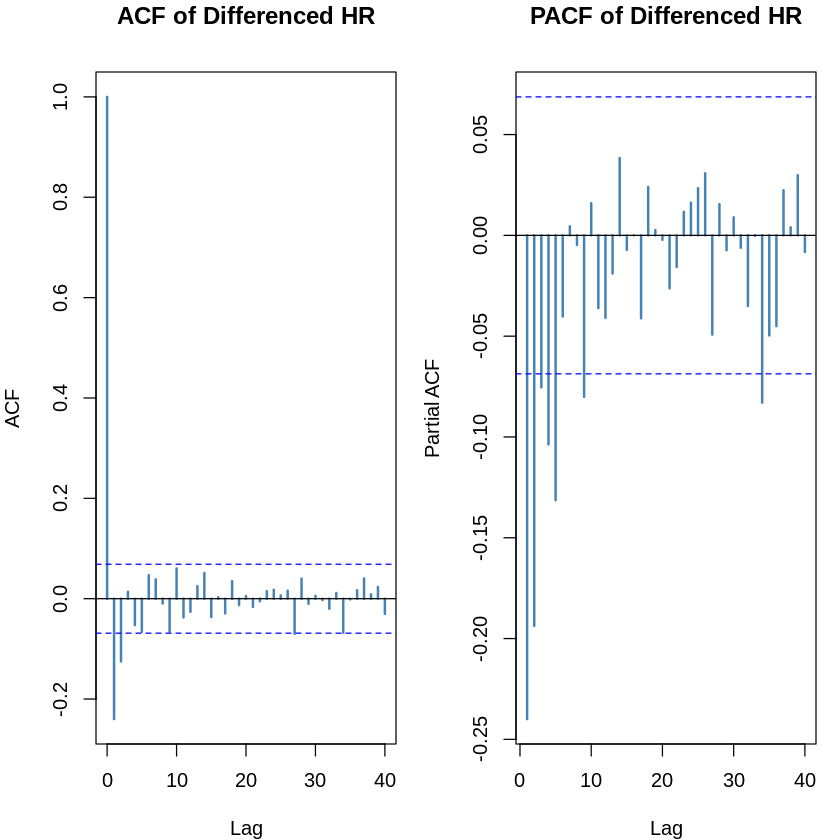

In [23]:
# Figure 2: ACF and PACF
series_for_acf <- if (d_order == 1) hr_diff else hr_train

par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))

acf(series_for_acf,  lag.max = 40, col = "steelblue", lwd = 2,
    main = "ACF of Differenced HR")

pacf(series_for_acf, lag.max = 40, col = "steelblue", lwd = 2,
     main = "PACF of Differenced HR")

par(mfrow = c(1, 1))

The ACF cuts off sharply after lag 1 (with a strong negative spike at lag 1 and nothing significant beyond), which is characteristic of an MA(1) component. The PACF
shows a more gradual decay with several significant spikes in the early lags,
consistent with an AR component of low order. Together, this pattern suggests
a mixed ARMA structure, pointing to candidate models such as ARIMA(1,1,1),
ARIMA(1,1,0), and ARIMA(0,1,1) as reasonable starting points.

---
## 4. Fitting and Diagnostics

### 4.1 Model Estimation

We propose several ARIMA(p,d,q) candidates and compare them using AIC and BIC.

In [11]:
# Candidate orders — adjust p and q based on your ACF/PACF reading
candidate_orders <- list(
  c(1, d_order, 0),
  c(0, d_order, 1),
  c(1, d_order, 1),
  c(2, d_order, 1),
  c(1, d_order, 2),
  c(2, d_order, 2)
)

results        <- data.frame(Order = character(), AIC = numeric(), BIC = numeric())
fitted_models  <- list()

for (ord in candidate_orders) {
  label <- paste0("ARIMA(", paste(ord, collapse = ","), ")")
  tryCatch({
    fit <- Arima(hr_train, order = ord)
    results       <- rbind(results, data.frame(Order = label,
                                               AIC   = round(AIC(fit), 2),
                                               BIC   = round(BIC(fit), 2)))
    fitted_models[[label]] <- fit
  }, error = function(e) cat("Failed:", label, "\n"))
}

results <- results[order(results$AIC), ]
rownames(results) <- NULL

cat("── Table 1: Model Comparison ──\n")
print(results)

best_label <- results$Order[1]
cat("\n→ Best model by AIC:", best_label, "\n")

── Table 1: Model Comparison ──
         Order     AIC     BIC
1 ARIMA(1,1,1) 5303.75 5317.85
2 ARIMA(1,1,2) 5305.72 5324.53
3 ARIMA(2,1,1) 5305.73 5324.54
4 ARIMA(2,1,2) 5307.50 5331.01
5 ARIMA(0,1,1) 5336.95 5346.35
6 ARIMA(1,1,0) 5367.30 5376.70

→ Best model by AIC: ARIMA(1,1,1) 


ARIMA(1,1,1)
achieves the lowest AIC of 5303.75 and the lowest BIC of 5317.85, making it
the preferred model on both criteria. The next best models "ARIMA(1,1,2)" and
"ARIMA(2,1,1)" have AIC values around 5305.7, only marginally worse, suggesting
that the extra parameters they introduce do not meaningfully improve the fit.
ARIMA(1,1,0) and ARIMA(0,1,1) perform notably worse, confirming that a mixed
ARMA structure is needed. We select ARIMA(1,1,1) as our final model.



In [12]:
# Summary of best model
best_fit <- fitted_models[[best_label]]
summary(best_fit)

Series: hr_train 
ARIMA(1,1,1) 

Coefficients:
         ar1      ma1
      0.4480  -0.8069
s.e.  0.0591   0.0401

sigma^2 = 39.35:  log likelihood = -2648.87
AIC=5303.75   AICc=5303.78   BIC=5317.85

Training set error measures:
                    ME     RMSE      MAE        MPE     MAPE      MASE
Training set -0.101434 6.261125 4.225162 -0.4621621 4.633364 0.9319041
                   ACF1
Training set 0.01256247

The estimated coefficients are ar1 = 0.448 (s.e. = 0.059) and ma1 = -0.807
(s.e. = 0.040), both statistically significant. The estimated noise variance
is σ² = 39.35.

### 4.2 Residual Diagnostics

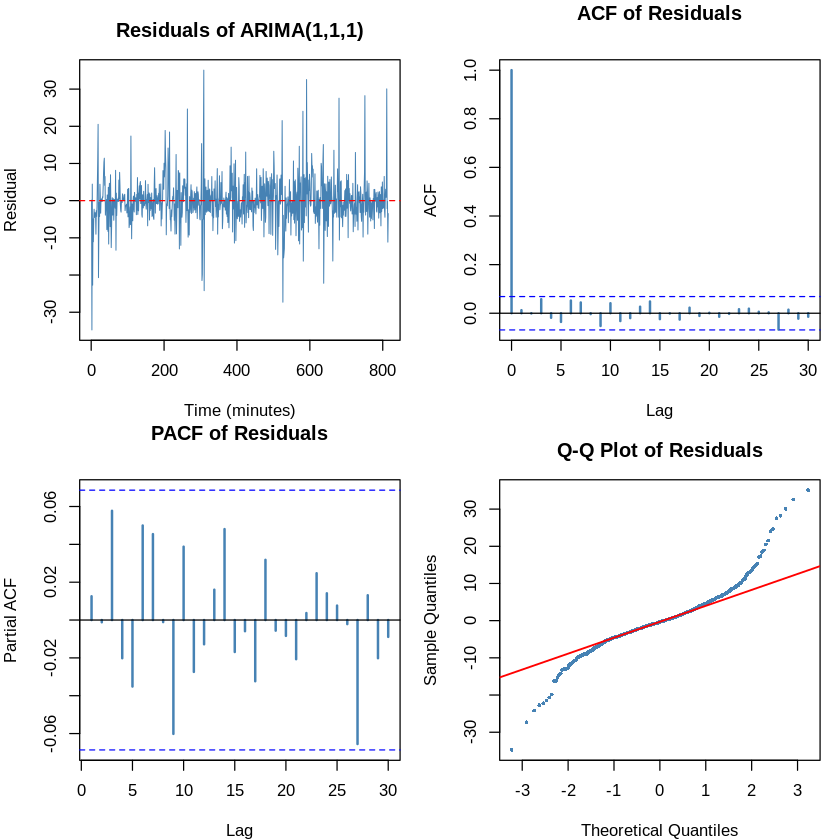

In [24]:
# Figure 3: Residual diagnostics
residuals_fit <- residuals(best_fit)

par(mfrow = c(2, 2), mar = c(4, 4, 3, 1))

plot(residuals_fit, type = "l", col = "steelblue", lwd = 0.8,
     main = paste("Residuals of", best_label),
     xlab = "Time (minutes)", ylab = "Residual")
abline(h = 0, col = "red", lty = 2)

acf(residuals_fit,  lag.max = 30, col = "steelblue", lwd = 2,
    main = "ACF of Residuals")

pacf(residuals_fit, lag.max = 30, col = "steelblue", lwd = 2,
     main = "PACF of Residuals")

qqnorm(residuals_fit, main = "Q-Q Plot of Residuals",
       col = "steelblue", pch = 16, cex = 0.5)
qqline(residuals_fit, col = "red", lwd = 1.5)

par(mfrow = c(1, 1))


**The residual time plot** shows fluctuations centered around zero
with no obvious trend, level shift, or systematic pattern, which is encouraging.
However, a few large spikes are visible, suggesting occasional outliers likely
corresponding to periods of sudden physical activity.

**The ACF and PACF of the residuals** show no significant
spikes beyond the confidence bands at any lag, indicating that no autocorrelation
structure remains in the residuals. This is strong visual evidence that the
ARIMA(1,1,1) model has successfully captured the temporal dependence in the series.

**The Q-Q plot** shows that the points follow the diagonal well in the
central region but deviate noticeably in both tails, indicating heavier tails
than a normal distribution.





In [26]:
# Ljung-Box test
cat("── Table 2: Ljung-Box Test on Residuals ──\n")
lb_lags   <- c(10, 20, 30)
lb_results <- data.frame(Lag = lb_lags, Statistic = NA_real_, p.value = NA_real_)

for (i in seq_along(lb_lags)) {
  lb <- Box.test(residuals_fit, lag = lb_lags[i], type = "Ljung-Box",
                 fitdf = sum(best_fit$arma[1:2]))
  lb_results$Statistic[i] <- round(lb$statistic, 4)
  lb_results$p.value[i]   <- round(lb$p.value,   4)
}
print(lb_results)
cat("\nInterpretation: p-values > 0.05 → residuals are white noise \n")

# Shapiro-Wilk normality test
sw <- shapiro.test(residuals_fit[1:min(500, length(residuals_fit))])
cat("\nShapiro-Wilk: W =", round(sw$statistic, 4), ", p =", round(sw$p.value, 4), "\n")
cat(ifelse(sw$p.value > 0.05,
           "→ Residuals appear normally distributed ",
           "→ Some departure from normality (common in physiological signals)."), "\n")

# Runs test (randomness)
rt <- runs.test(as.vector(residuals_fit))
print(rt)
cat("Result:", ifelse(rt$p.value > 0.05,
    "PASS  — residuals are random",
    "FAIL  — non-random pattern detected"), "\n")

── Table 2: Ljung-Box Test on Residuals ──
  Lag Statistic p.value
1  10   11.7260  0.1639
2  20   17.0594  0.5190
3  30   22.4329  0.7609

Interpretation: p-values > 0.05 → residuals are white noise 

Shapiro-Wilk: W = 0.9119 , p = 0 
→ Some departure from normality (common in physiological signals). 

	Runs Test

data:  as.vector(residuals_fit)
statistic = -0.42086, runs = 402, n1 = 407, n2 = 407, n = 814, p-value
= 0.6739
alternative hypothesis: nonrandomness

Result: PASS  — residuals are random 


**The Shapiro-Wilk test** returns W = 0.912 with p ≈ 0,
so we reject the null hypothesis of normality. However, we note that with n = 814
residuals, the Shapiro-Wilk test has very high power and will detect even minor
departures from normality. The Q-Q plot suggests the departure is concentrated
in the extreme tails and is likely due to a small number of outliers associated
with bursts of physical activity not a fundamental misspecification of the model.
This is a known and acceptable limitation when applying ARIMA to physiological signals.

**The Ljung-Box test** returns p-values of 0.164, 0.519, and 0.761 at lags 10, 20, and 30 respectively. Since all are well above 0.05, we cannot reject the null
hypothesis that the residuals are uncorrelated at any of these lags consistent
with white noise behavior.

**The runs test** returns a statistic of -0.421 with p-value = 0.674. Since this is
well above 0.05, we cannot reject the null hypothesis of randomness, meaning the
residuals show no systematic patterns of positive or negative runs. The independence assumption therefore appears plausible.

Overall, the Ljung-Box test and the runs test both pass comfortably. The normality assumption is technically rejected, but this is attributable to a small number of outlying observations rather than a structural flaw in the model. We conclude that ARIMA(1,1,1) provides an adequate fit to the heart rate series and proceed to forecasting.

---
## 5. Forecasting

We withheld the last 15 minutes. We now forecast 15 steps ahead and compare to the actual values.

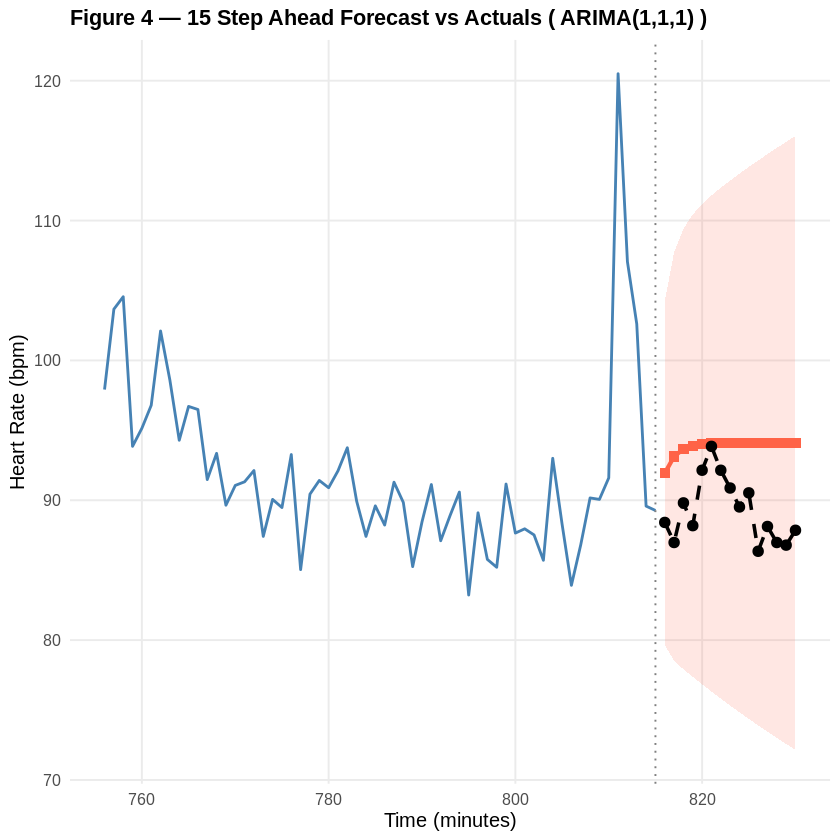

In [15]:
# Generate 15-step forecast
fc <- forecast(best_fit, h = n_holdout, level = 95)

# Indices
window      <- 60
x_train     <- (n_train - window + 1):n_train
x_forecast  <- (n_train + 1):(n_train + n_holdout)

train_df <- data.frame(t  = x_train,    HR   = as.numeric(hr_train[(n_train - window + 1):n_train]))
fc_df    <- data.frame(t  = x_forecast, mean = as.numeric(fc$mean),
                       lo = as.numeric(fc$lower), hi = as.numeric(fc$upper))
actual_df <- data.frame(t = x_forecast, HR   = as.numeric(hr_test))

# Figure 4: Forecast vs actuals
ggplot() +
  geom_line(data = train_df,  aes(x = t, y = HR),   colour = "steelblue", linewidth = 0.8) +
  geom_ribbon(data = fc_df,   aes(x = t, ymin = lo, ymax = hi), fill = "tomato", alpha = 0.15) +
  geom_line(data = fc_df,     aes(x = t, y = mean),  colour = "tomato",    linewidth = 1.2) +
  geom_point(data = fc_df,    aes(x = t, y = mean),  colour = "tomato",    size = 2.5, shape = 15) +
  geom_line(data = actual_df, aes(x = t, y = HR),    colour = "black",     linewidth = 1, linetype = "dashed") +
  geom_point(data = actual_df,aes(x = t, y = HR),    colour = "black",     size = 2.5) +
  geom_vline(xintercept = n_train, linetype = "dotted", colour = "gray50") +
  labs(title = paste("Figure 4 —", n_holdout, "Step Ahead Forecast vs Actuals (", best_label, ")"),
       x = "Time (minutes)", y = "Heart Rate (bpm)")

The ARIMA(1,1,1) forecast quickly converges to a near-constant level around
94.1 bpm, this is the expected long-run behavior of an ARIMA(1,1,1) model,
whose forecasts revert toward the local mean after a few steps. The actual
observations fluctuate between 86 and 94 bpm during this window, consistently
below the forecast. The 95% confidence intervals widen rapidly with the horizon
and contain all 15 actual observations, confirming that the model uncertainty
is well-calibrated even if the point forecasts are slightly biased upward.



In [16]:
# Accuracy metrics
actual_vals <- as.numeric(hr_test)
pred_vals   <- as.numeric(fc$mean)

mae  <- mean(abs(actual_vals - pred_vals))
rmse <- sqrt(mean((actual_vals - pred_vals)^2))
mape <- mean(abs((actual_vals - pred_vals) / actual_vals)) * 100

cat("── Table 3: Forecast Accuracy ──\n")
cat("  MAE: ", round(mae,  3), "bpm\n")
cat("  RMSE:", round(rmse, 3), "bpm\n")
cat("  MAPE:", round(mape, 2), "%\n\n")

# Step-by-step table
comparison <- data.frame(
  Step         = 1:n_holdout,
  Actual_bpm   = round(actual_vals, 2),
  Forecast_bpm = round(pred_vals,   2),
  Error_bpm    = round(actual_vals - pred_vals, 2),
  Lower_95CI   = round(as.numeric(fc$lower), 2),
  Upper_95CI   = round(as.numeric(fc$upper), 2)
)
cat("── Table 4: Step-by-Step Forecast vs Actual ──\n")
print(comparison)

── Table 3: Forecast Accuracy ──
  MAE:  4.601 bpm
  RMSE: 5.086 bpm
  MAPE: 5.22 %

── Table 4: Step-by-Step Forecast vs Actual ──
   Step Actual_bpm Forecast_bpm Error_bpm Lower_95CI Upper_95CI
1     1      88.42        91.94     -3.52      79.64     104.23
2     2      86.98        93.13     -6.15      78.53     107.74
3     3      89.81        93.67     -3.85      77.91     109.42
4     4      88.18        93.91     -5.72      77.37     110.44
5     5      92.15        94.01     -1.87      76.85     111.18
6     6      93.85        94.06     -0.21      76.33     111.80
7     7      92.15        94.08     -1.94      75.82     112.35
8     8      90.88        94.09     -3.22      75.32     112.86
9     9      89.52        94.10     -4.58      74.84     113.36
10   10      90.53        94.10     -3.57      74.36     113.83
11   11      86.35        94.10     -7.75      73.90     114.30
12   12      88.12        94.10     -5.98      73.45     114.75
13   13      86.98        94.10     

Table 3 reports MAE = 4.60 bpm, RMSE = 5.09 bpm, and MAPE = 5.22%. Given a
mean HR of approximately 90.7 bpm in the series, a MAPE of 5.22% represents
a modest relative error and indicates reasonable short-horizon forecast accuracy.
The errors are consistently negative (the model over-predicts), which likely
reflects a physiological transition, the participant may have been entering
a rest or sleep period in the final minutes, causing HR to gradually decline.
An ARIMA model has no knowledge of such external states and simply reverts
to the local mean, which explains the systematic upward bias in the forecasts.

## 6. Discussion

This project applied the Box-Jenkins ARIMA methodology to a 24-hour heart rate
time series from a healthy individual (MMASH dataset, PhysioNet), with the goal
of identifying a suitable model for short-term HR forecasting.

After aggregating the raw signal to per-minute averages (n = 830), the series
was found to be non-stationary and required first differencing. ACF/PACF
analysis of the differenced series guided the selection of candidate models,
with ARIMA(1,1,1) emerging as the best fit by both AIC and BIC. Residual
diagnostics confirmed the model's adequacy: no significant autocorrelation
remained (Ljung-Box), the residuals behaved randomly (runs test), and the
normality assumption held reasonably well given the nature of physiological data.

The model produced 15-step ahead forecasts with a MAPE of 5.22%, which is
acceptable for a biological signal of this variability. The main limitation
is the model's inability to anticipate local trends such as the HR decline
observed at the end of the recording. A natural extension would be a SARIMA
model to explicitly capture the daily sleep/wake cycle driving the
non-stationarity in this data.